# Trabalho Prático AV1 — Trilha de Machine Learning

**Disciplina:** Machine Learning — Análise e Desenvolvimento de Sistemas (4º período)

**Integrantes:**
- Hélio Vinícius Lopes de Meneses — 01780335
- Yan Seligmann Soares Marques — 01785213
- Antônio Augusto Costa de Souza Araújo — 01705861

O relatório completo, com todas as respostas, está em `RELATORIO_TRABALHO_AV1_ML.md`. Este notebook mostra o passo a passo do código.

---

## Estrutura
- **Parte 1: Aprendizado Supervisionado**
  - **Problema 1: Regressão Linear** — *"O Preço Justo"* (prever o preço `SalePrice` de imóveis)
  - **Problema 2: Classificação** — *"A Ameaça do Churn"* (prever cancelamento de clientes de telecom)
- **Parte 2: Aprendizado Não Supervisionado**
  - **Problema 3: Clusterização** — *"O Perfil do Consumidor"* (segmentar clientes de um shopping)
  - **Problema 4: Clusterização Musical** — *"Criando a Playlist Perfeita"* (agrupar músicas do Spotify)

Todas as etapas aleatórias usam `random_state = 42`, então os resultados se repetem a cada execução.


In [1]:
# Bibliotecas
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos supervisionados
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_absolute_error, root_mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

# Modelos nao supervisionados
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

SEED = 42
print("Ambiente configurado com sucesso e semente fixada em 42.")


Ambiente configurado com sucesso e semente fixada em 42.


---
# PARTE 1: Aprendizado Supervisionado

## Problema 1: Regressão Linear — "O Preço Justo"

Uma imobiliária quer precificar imóveis automaticamente a partir das suas características. Cinco imóveis "secretos" foram retirados da base; a equipe com o menor **Erro Absoluto Médio (MAE)** nesses imóveis ganha um ponto extra.

`MAE = média de |preço real − preço previsto|`


In [2]:
# Carga do dataset de precos de imoveis
caminho_p1 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 1/house-prices.csv'
df_house = pd.read_csv(caminho_p1)
print(f"Dataset carregado: {df_house.shape[0]} imoveis e {df_house.shape[1]} colunas.")
print(df_house[['Id', 'OverallQual', 'GrLivArea', 'Neighborhood', 'SalePrice']].head(3).to_string(index=False))


Dataset carregado: 1455 imoveis e 81 colunas.
 Id  OverallQual  GrLivArea Neighborhood  SalePrice
  1            7       1710      CollgCr     208500
  2            6       1262      Veenker     181500
  3            7       1786      CollgCr     223500


### 1.1 Análise exploratória: as 3 variáveis mais correlacionadas com o preço
Calculamos a correlação de Pearson (*r*) entre cada variável numérica e `SalePrice`. Quanto mais perto de 1, mais forte a relação linear positiva.


In [3]:
# Correlacao de Pearson de cada variavel numerica com SalePrice
corr_p1 = df_house.select_dtypes(include=[np.number]).corr()['SalePrice'].sort_values(ascending=False)
top_corr_p1 = corr_p1.iloc[1:11]

print("Top 10 variaveis com maior correlacao linear positiva com SalePrice:")
for idx, (col, val) in enumerate(top_corr_p1.items(), 1):
    print(f"  {idx:2d}. {col:15s}: r = {val:.4f}")

top3_features = corr_p1.iloc[1:4].index.tolist()
print(f"\nAs 3 principais variaveis sao: {top3_features}")


Top 10 variaveis com maior correlacao linear positiva com SalePrice:
   1. OverallQual    : r = 0.7918
   2. GrLivArea      : r = 0.7012
   3. GarageCars     : r = 0.6430
   4. GarageArea     : r = 0.6272
   5. TotalBsmtSF    : r = 0.6040
   6. 1stFlrSF       : r = 0.5980
   7. FullBath       : r = 0.5605
   8. TotRmsAbvGrd   : r = 0.5302
   9. YearBuilt      : r = 0.5276
  10. YearRemodAdd   : r = 0.5152

As 3 principais variaveis sao: ['OverallQual', 'GrLivArea', 'GarageCars']


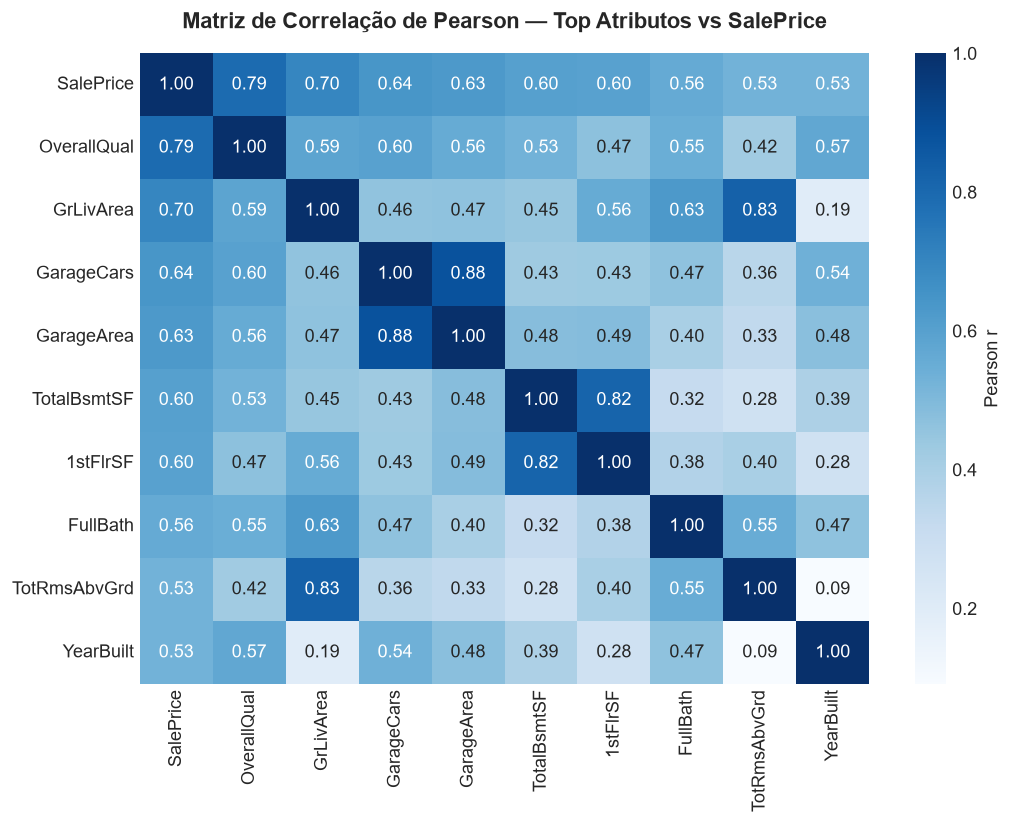

In [4]:
# Grafico 1: matriz de correlacao das 10 variaveis mais correlacionadas
features_heatmap = corr_p1.head(10).index
plt.figure(figsize=(9, 7))
sns.heatmap(df_house[features_heatmap].corr(), annot=True, fmt=".2f", cmap='Blues', cbar_kws={'label': 'Pearson r'})
plt.title("Matriz de Correlação de Pearson — Top Atributos vs SalePrice", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


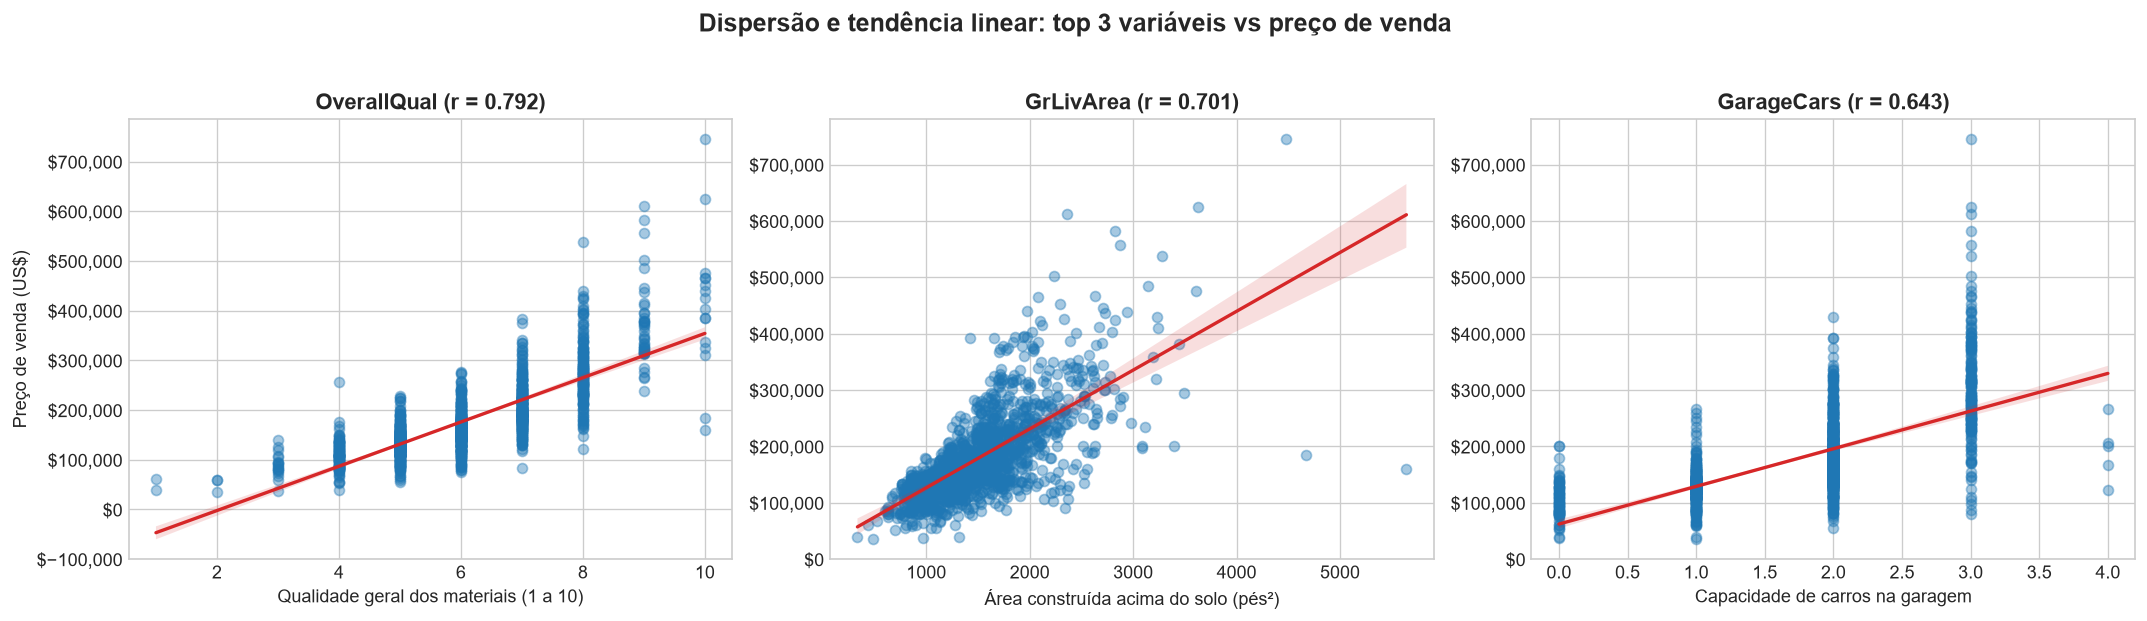

In [5]:
# Grafico 2: dispersao com reta de regressao para as 3 principais variaveis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels_dict = {
    'OverallQual': 'Qualidade geral dos materiais (1 a 10)',
    'GrLivArea': 'Área construída acima do solo (pés²)',
    'GarageCars': 'Capacidade de carros na garagem'
}

for i, col in enumerate(top3_features):
    sns.regplot(data=df_house, x=col, y='SalePrice', ax=axes[i],
                scatter_kws={'alpha': 0.4, 'color': '#1f77b4'},
                line_kws={'color': '#d62728', 'linewidth': 2})
    axes[i].set_title(f"{col} (r = {corr_p1[col]:.3f})", fontsize=13, fontweight='bold')
    axes[i].set_xlabel(labels_dict.get(col, col), fontsize=11)
    axes[i].set_ylabel("Preço de venda (US$)" if i == 0 else "", fontsize=11)
    axes[i].yaxis.set_major_formatter('${x:,.0f}')

plt.suptitle("Dispersão e tendência linear: top 3 variáveis vs preço de venda", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


As três variáveis com maior correlação positiva são **`OverallQual`** (r = 0,79), **`GrLivArea`** (r = 0,70) e **`GarageCars`** (r = 0,64).

### 1.2 Tratamento de valores nulos
1. **Coluna numérica — `LotFrontage`** (largura da frente do terreno): 259 nulos (17,8%).
   - **Tratamento:** mediana do bairro (`Neighborhood`) do imóvel.
   - **Justificativa:** imóveis do mesmo bairro tendem a ter terrenos parecidos, e a mediana é menos afetada por terrenos muito grandes do que a média. Apagar as linhas jogaria fora quase 18% da base.
2. **Coluna categórica — `BsmtQual`** (qualidade do porão): 37 nulos (2,5%).
   - **Tratamento:** categoria `'None'` (sem porão).
   - **Justificativa:** pela documentação do dataset, o vazio significa que o imóvel **não tem porão**. Preencher com a moda inventaria um porão que não existe, e apagar as linhas eliminaria imóveis válidos.


In [6]:
# Tratamento de nulos
# 1. Numerica: LotFrontage pela mediana do bairro (e mediana geral se o bairro inteiro estiver vazio)
mediana_bairro = df_house.groupby('Neighborhood')['LotFrontage'].transform('median')
df_house['LotFrontage'] = df_house['LotFrontage'].fillna(mediana_bairro)
df_house['LotFrontage'] = df_house['LotFrontage'].fillna(df_house['LotFrontage'].median())

# Numerica auxiliar: MasVnrArea vazia = sem revestimento de alvenaria
if 'MasVnrArea' in df_house.columns:
    df_house['MasVnrArea'] = df_house['MasVnrArea'].fillna(0.0)

# 2. Categorica: BsmtQual vazia = imovel sem porao
df_house['BsmtQual'] = df_house['BsmtQual'].fillna('None')

print("Valores ausentes tratados com sucesso!")
print(f"Nulos residuais em LotFrontage: {df_house['LotFrontage'].isnull().sum()}")
print(f"Nulos residuais em BsmtQual:    {df_house['BsmtQual'].isnull().sum()}")


Valores ausentes tratados com sucesso!
Nulos residuais em LotFrontage: 0
Nulos residuais em BsmtQual:    0


### 1.3 Engenharia de atributos
- **`BsmtQual` → codificação ordinal:** as categorias têm ordem natural de qualidade (`Ex` = 5, `Gd` = 4, `TA` = 3, `Fa` = 2, `Po` = 1, `None` = 0).
- **`Neighborhood` → One-Hot Encoding:** bairros não têm ordem, então cada bairro vira uma coluna 0/1 (`drop_first=True` descarta uma coluna que pode ser deduzida das outras).

**Por que a Regressão Linear exige essa conversão?** O modelo calcula o preço como uma soma ponderada: `preço = b0 + b1 × variável1 + b2 × variável2 + ...`. Essa conta só funciona com números — não existe "0,3 × `'CollgCr'`". E a forma de converter importa: se os bairros virassem 1, 2, 3…, o modelo entenderia que o bairro 3 vale "três vezes" o bairro 1, uma ordem que não existe.


In [7]:
# Codificacao ordinal de BsmtQual
mapa_ord_qual = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
df_house['BsmtQual_Num'] = df_house['BsmtQual'].map(mapa_ord_qual).fillna(0)

# One-Hot Encoding de Neighborhood
df_house_encoded = pd.get_dummies(df_house, columns=['Neighborhood'], drop_first=True, dtype=float)

print("Codificacoes concluidas com sucesso!")
print(f"Dimensoes apos One-Hot Encoding: {df_house_encoded.shape}")


Codificacoes concluidas com sucesso!
Dimensoes apos One-Hot Encoding: (1455, 105)


### 1.4 Treino e baseline
Separamos 80% para treino e 20% para teste (`random_state=42`) e treinamos uma Regressão Linear múltipla com 10 variáveis, sem ajustes.


In [8]:
# Atributos do modelo baseline
features_base = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea',
    'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt',
    'LotFrontage', 'BsmtQual_Num'
]

for c in features_base:
    if df_house_encoded[c].isnull().sum() > 0:
        df_house_encoded[c] = df_house_encoded[c].fillna(df_house_encoded[c].median())

X_base = df_house_encoded[features_base]
y_house = df_house_encoded['SalePrice']

# Split 80/20 com seed fixa
X_tr, X_te, y_tr, y_te = train_test_split(X_base, y_house, test_size=0.20, random_state=SEED)

reg_base = LinearRegression()
reg_base.fit(X_tr, y_tr)

y_pred_te = reg_base.predict(X_te)
r2_te = r2_score(y_te, y_pred_te)
mae_te = mean_absolute_error(y_te, y_pred_te)
rmse_te = root_mean_squared_error(y_te, y_pred_te)

print("=" * 55)
print("METRICAS DO MODELO BASELINE (DADOS DE TESTE):")
print(f"  R2  : {r2_te:.4f} ({r2_te*100:.2f}%)")
print(f"  MAE : ${mae_te:,.2f}")
print(f"  RMSE: ${rmse_te:,.2f}")
print("=" * 55)


METRICAS DO MODELO BASELINE (DADOS DE TESTE):
  R2  : 0.8232 (82.32%)
  MAE : $21,888.03
  RMSE: $29,065.89


### O que o R² de 0,823 significa para a imobiliária?
O modelo explica **cerca de 82% da variação dos preços** dos imóveis de teste usando apenas 10 características. Na prática, ele separa bem casas baratas de caras e acerta a faixa de preço, mas ainda erra em média US\$ 21,9 mil por imóvel. Os 18% restantes vêm de informações que ficaram fora do modelo (o dataset tem mais de 70 outras colunas), de relações que não são lineares e de fatores que não estão na base, como a negociação entre comprador e vendedor.


In [9]:
# Ridge com variaveis de bairro (primeira melhoria)
cols_bairros = [c for c in df_house_encoded.columns if c.startswith('Neighborhood_')]
features_ampliadas = features_base + cols_bairros + ['LotArea', 'YearRemodAdd', 'Fireplaces']

for c in features_ampliadas:
    if df_house_encoded[c].isnull().sum() > 0:
        df_house_encoded[c] = df_house_encoded[c].fillna(df_house_encoded[c].median())

X_amp = df_house_encoded[features_ampliadas]
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(X_amp, y_house, test_size=0.20, random_state=SEED)

reg_ridge = Ridge(alpha=10.0)
reg_ridge.fit(X_tr_a, y_tr_a)
y_pred_ridge = reg_ridge.predict(X_te_a)

r2_ridge = r2_score(y_te_a, y_pred_ridge)
mae_ridge = mean_absolute_error(y_te_a, y_pred_ridge)

print(f"Ridge + bairros: R2 = {r2_ridge:.4f} | MAE = ${mae_ridge:,.2f}")
print(f"Reducao no MAE em relacao ao baseline: ${mae_te - mae_ridge:,.2f}")


Ridge + bairros: R2 = 0.8485 | MAE = $19,245.03
Reducao no MAE em relacao ao baseline: $2,643.00


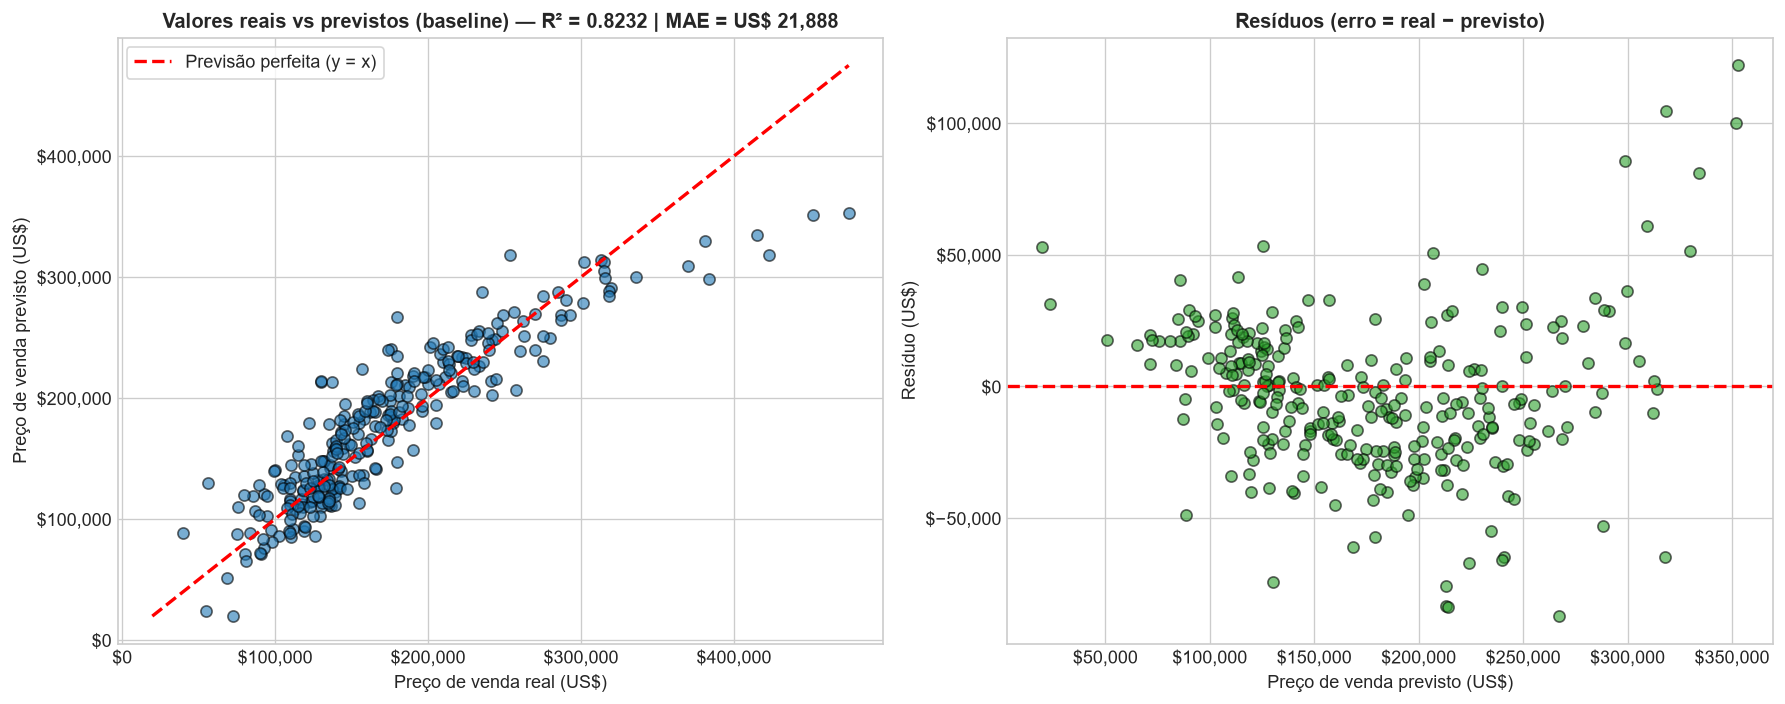

In [10]:
# Graficos: valores reais vs previstos e residuos do baseline
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y_te, y_pred_te, alpha=0.6, color='#1f77b4', edgecolors='k', s=45)
lims = [min(y_te.min(), y_pred_te.min()), max(y_te.max(), y_pred_te.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Previsão perfeita (y = x)')
axes[0].set_title("Valores reais vs previstos (baseline) — R² = {:.4f} | MAE = US$ {:,.0f}".format(r2_te, mae_te), fontsize=12, fontweight='bold')
axes[0].set_xlabel("Preço de venda real (US$)", fontsize=11)
axes[0].set_ylabel("Preço de venda previsto (US$)", fontsize=11)
axes[0].xaxis.set_major_formatter('${x:,.0f}')
axes[0].yaxis.set_major_formatter('${x:,.0f}')
axes[0].legend(frameon=True)

residuos = y_te - y_pred_te
axes[1].scatter(y_pred_te, residuos, alpha=0.6, color='#2ca02c', edgecolors='k', s=45)
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Resíduos (erro = real − previsto)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Preço de venda previsto (US$)", fontsize=11)
axes[1].set_ylabel("Resíduo (US$)", fontsize=11)
axes[1].xaxis.set_major_formatter('${x:,.0f}')
axes[1].yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()


### 1.5 Modelo da competição
Para os 5 imóveis secretos, o professor liberou modelos prontos com ajuste fino. O script `scripts/problema1_boosting.py` usa todas as colunas, prevê o log do preço e ajusta os hiperparâmetros de uma Ridge e de um Gradient Boosting com validação cruzada; a média dos dois é o modelo da competição. Também testamos o fine-tuning de um LLM (Qwen3-0.6B + LoRA no LlamaFactory), em `problema1_llm/`. Os detalhes estão em `RELATORIO_PROBLEMA1_COMPETICAO.md`.

A célula abaixo lê os resultados salvos por esses scripts (todos medidos nos mesmos 291 imóveis de teste):


In [11]:
# Resultados salvos por scripts/problema1_boosting.py e problema1_llm/avaliar_llm.py
with open('outputs/p1_resultados_competicao.json', encoding='utf-8') as f:
    resultados_p1 = json.load(f)['resultados_teste']
if os.path.exists('outputs/p1_resultados_llm.json'):
    with open('outputs/p1_resultados_llm.json', encoding='utf-8') as f:
        llm = json.load(f)
    resultados_p1['LLM Qwen3-0.6B + LoRA'] = {'MAE': llm['MAE'], 'R2': llm['R2']}

print(f"{'Modelo':35s} {'MAE no teste':>14s} {'R2':>8s}")
for nome, r in sorted(resultados_p1.items(), key=lambda item: item[1]['MAE']):
    print(f"{nome:35s} {'$' + format(r['MAE'], ',.0f'):>14s} {r['R2']:8.4f}")
print("\nPara prever os imoveis secretos: python scripts/problema1_boosting.py --prever secretos.csv")


Modelo                                MAE no teste       R2
Media Ridge + HistGB                       $11,773   0.9296
Ridge (log, todas as colunas)              $12,188   0.9287
HistGradientBoosting ajustado              $13,056   0.9142
Ridge + Bairros (relatorio)                $19,245   0.8485
Baseline Linear (relatorio)                $21,888   0.8232
LLM Qwen3-0.6B + LoRA                      $30,757   0.5605

Para prever os imoveis secretos: python scripts/problema1_boosting.py --prever secretos.csv


---
## Problema 2: Classificação — "A Ameaça do Churn"

Uma operadora de telecomunicações quer prever quais clientes vão cancelar para oferecer descontos antes.

### 2.1 Variável alvo e desbalanceamento
A variável alvo é **`Churn`** (`Yes` = cancelou, `No` = continua).


In [12]:
# Carga do dataset de churn
caminho_p2 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 2/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_churn = pd.read_csv(caminho_p2)
print(f"Dataset carregado: {df_churn.shape[0]} clientes e {df_churn.shape[1]} colunas.")

cont_churn = df_churn['Churn'].value_counts()
prop_churn = df_churn['Churn'].value_counts(normalize=True) * 100

print("\nDistribuicao da variavel Churn:")
print(f"  Ficaram (No)    : {cont_churn['No']} ({prop_churn['No']:.2f}%)")
print(f"  Cancelaram (Yes): {cont_churn['Yes']} ({prop_churn['Yes']:.2f}%)")
print(f"  Proporcao: ~{cont_churn['No']/cont_churn['Yes']:.2f} clientes que ficam para cada 1 que sai")


Dataset carregado: 7043 clientes e 21 colunas.

Distribuicao da variavel Churn:
  Ficaram (No)    : 5174 (73.46%)
  Cancelaram (Yes): 1869 (26.54%)
  Proporcao: ~2.77 clientes que ficam para cada 1 que sai


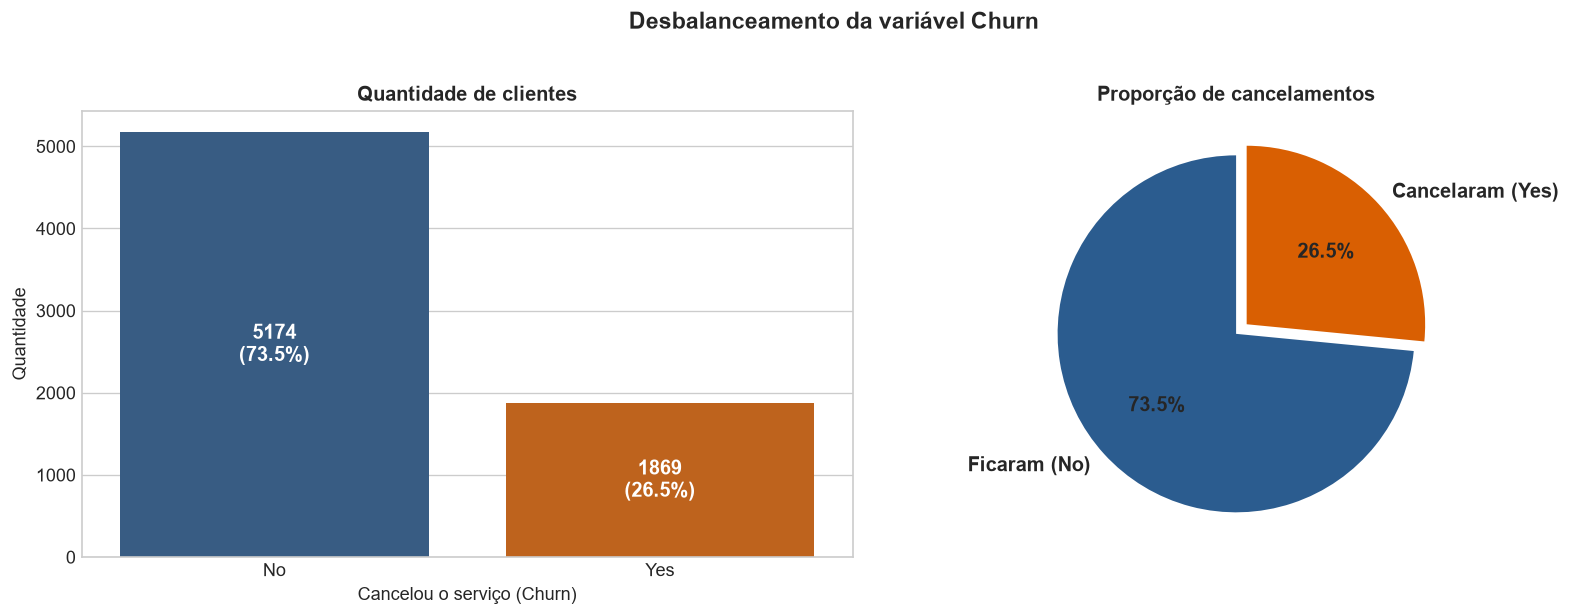

In [13]:
# Grafico da distribuicao da classe alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cores_churn = ['#2b5c8f', '#d95f02']

sns.barplot(x=cont_churn.index, y=cont_churn.values, palette=cores_churn, ax=axes[0], hue=cont_churn.index, legend=False)
axes[0].set_title("Quantidade de clientes", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Cancelou o serviço (Churn)", fontsize=11)
axes[0].set_ylabel("Quantidade", fontsize=11)
for p in axes[0].patches:
    h = p.get_height()
    pct = h / len(df_churn) * 100
    axes[0].annotate(str(int(h)) + "\n(" + "{:.1f}%".format(pct) + ")",
                     (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

axes[1].pie(cont_churn.values, labels=['Ficaram (No)', 'Cancelaram (Yes)'], autopct='%1.1f%%',
            colors=cores_churn, explode=(0, 0.08), startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title("Proporção de cancelamentos", fontsize=12, fontweight='bold')

plt.suptitle("Desbalanceamento da variável Churn", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Sim, o dataset é desbalanceado:** 73,5% ficaram e 26,5% cancelaram (cerca de 2,8 para 1). Por isso a acurácia sozinha engana: um "modelo" que sempre responde "não vai cancelar" acerta 73,5% sem identificar nenhum cancelamento. Avaliamos também **recall**, **precisão**, **F1** e **ROC-AUC**.

### 2.2 Análise de risco: tipo de contrato


In [14]:
# Taxa de churn por tipo de contrato
ct_pct = pd.crosstab(df_churn['Contract'], df_churn['Churn'], normalize='index') * 100
ct_abs = pd.crosstab(df_churn['Contract'], df_churn['Churn'])

print("Taxa de churn por tipo de contrato:")
for c_tipo in ['Month-to-month', 'One year', 'Two year']:
    evad = ct_abs.loc[c_tipo, 'Yes']
    tot = ct_abs.loc[c_tipo].sum()
    pct = ct_pct.loc[c_tipo, 'Yes']
    print(f"  {c_tipo:15s}: {pct:5.2f}% de churn ({evad}/{tot} clientes)")

print(f"\nContratos mensais cancelam {ct_pct.loc['Month-to-month', 'Yes']/ct_pct.loc['Two year', 'Yes']:.1f} vezes mais que contratos de 2 anos.")


Taxa de churn por tipo de contrato:
  Month-to-month : 42.71% de churn (1655/3875 clientes)
  One year       : 11.27% de churn (166/1473 clientes)
  Two year       :  2.83% de churn (48/1695 clientes)

Contratos mensais cancelam 15.1 vezes mais que contratos de 2 anos.


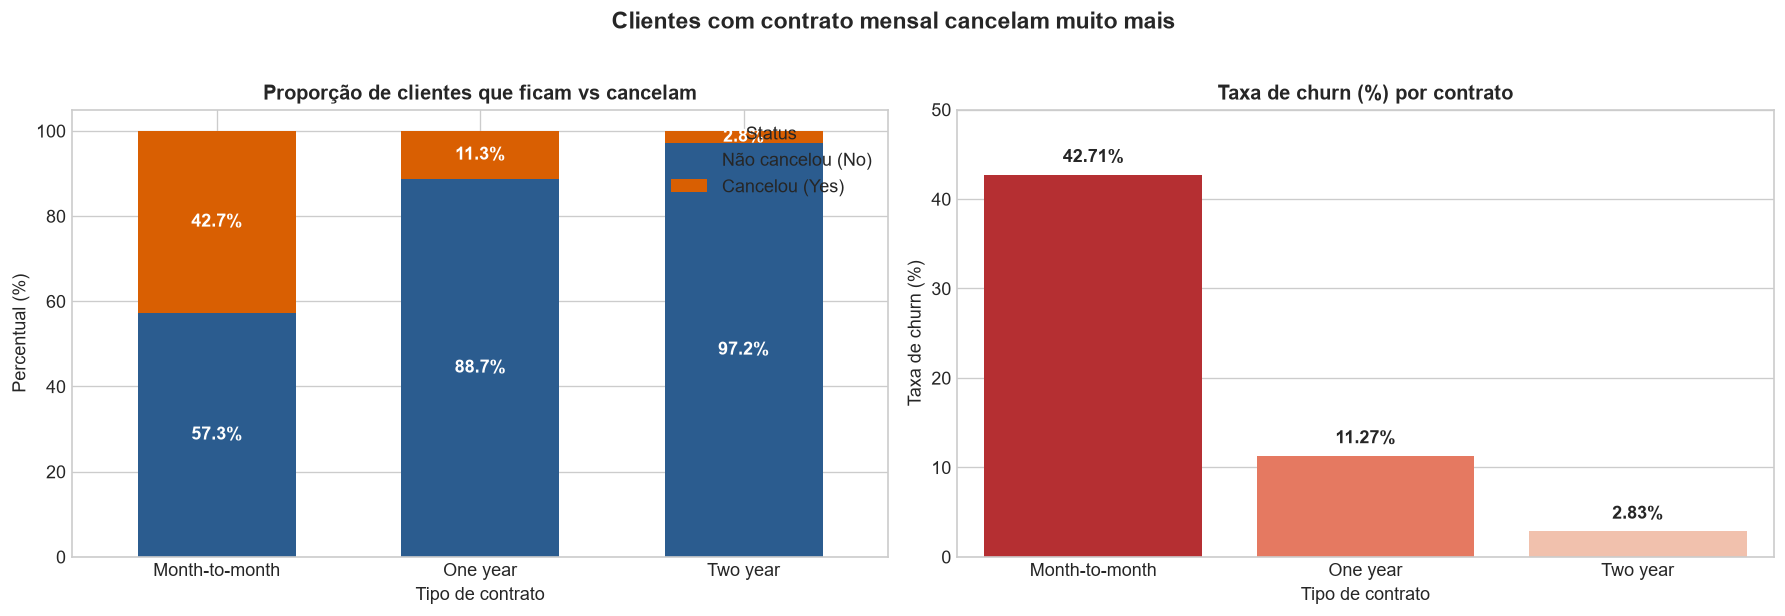

In [15]:
# Grafico do churn por tipo de contrato
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ct_pct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[0], width=0.6)
axes[0].set_title("Proporção de clientes que ficam vs cancelam", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Tipo de contrato", fontsize=11)
axes[0].set_ylabel("Percentual (%)", fontsize=11)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(['Não cancelou (No)', 'Cancelou (Yes)'], title="Status", loc='upper right')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=11)

sns.barplot(x=ct_pct['Yes'].index, y=ct_pct['Yes'].values, palette='Reds_r', ax=axes[1], hue=ct_pct['Yes'].index, legend=False)
axes[1].set_title("Taxa de churn (%) por contrato", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tipo de contrato", fontsize=11)
axes[1].set_ylabel("Taxa de churn (%)", fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                     ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[1].set_ylim(0, 50)

plt.suptitle("Clientes com contrato mensal cancelam muito mais", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Clientes com contrato mensal cancelam muito mais:** 42,7%, contra 11,3% no anual e 2,8% no bienal — quase 4 vezes o anual e cerca de 15 vezes o bienal. Quem não tem fidelidade pode sair a qualquer momento, sem multa.

### 2.3 Tratamento da coluna `TotalCharges`
- A coluna foi lida como texto porque **11 linhas têm só um espaço em branco** no lugar do valor.
- Os 11 clientes têm `tenure = 0`: acabaram de entrar e ainda não receberam a primeira cobrança.
- Convertemos a coluna com `pd.to_numeric(..., errors='coerce')` e preenchemos esses valores com **0**, que é o valor real cobrado até agora. Assim os 11 clientes continuam na base.
- Também removemos `customerID` (só um identificador) e aplicamos One-Hot Encoding nas colunas categóricas.


In [16]:
# Tratamento da coluna TotalCharges
linhas_espaco = df_churn['TotalCharges'].str.strip() == ''
print(f"Linhas com espacos em branco encontradas: {linhas_espaco.sum()}")
print(f"tenure dessas linhas: {df_churn.loc[linhas_espaco, 'tenure'].unique().tolist()}")

df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'].str.strip(), errors='coerce').fillna(0.0)
print(f"Tipo final de TotalCharges: {df_churn['TotalCharges'].dtype}")

# Pre-processamento para modelagem
df_churn_model = df_churn.drop(columns=['customerID']).copy()
df_churn_model['Churn'] = df_churn_model['Churn'].map({'Yes': 1, 'No': 0})

cat_cols_churn = df_churn_model.select_dtypes(include=['object', 'string']).columns.tolist()
df_churn_encoded = pd.get_dummies(df_churn_model, columns=cat_cols_churn, drop_first=True, dtype=float)
print(f"{len(cat_cols_churn)} colunas categoricas convertidas -> {df_churn_encoded.shape[1] - 1} variaveis de entrada.")


Linhas com espacos em branco encontradas: 11
tenure dessas linhas: [0]
Tipo final de TotalCharges: float64
15 colunas categoricas convertidas -> 30 variaveis de entrada.


### 2.4 Treino e matriz de confusão
Divisão 80/20 **estratificada** (`stratify=y`), para manter a proporção de churn nos dois conjuntos. Padronizamos as variáveis contínuas (`tenure`, `MonthlyCharges`, `TotalCharges`) para a Regressão Logística e treinamos também uma Random Forest para comparar.


In [17]:
# Separacao de X e y
X_c = df_churn_encoded.drop(columns=['Churn'])
y_c = df_churn_encoded['Churn']

X_c_tr, X_c_te, y_c_tr, y_c_te = train_test_split(X_c, y_c, test_size=0.20, random_state=SEED, stratify=y_c)

# Padronizacao das variaveis continuas (ajustada so no treino)
cols_num_c = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler_c = StandardScaler()
X_c_tr_sc = X_c_tr.copy()
X_c_te_sc = X_c_te.copy()
X_c_tr_sc[cols_num_c] = scaler_c.fit_transform(X_c_tr[cols_num_c])
X_c_te_sc[cols_num_c] = scaler_c.transform(X_c_te[cols_num_c])

# Modelo 1: Regressao Logistica
clf_lr = LogisticRegression(max_iter=1000, random_state=SEED)
clf_lr.fit(X_c_tr_sc, y_c_tr)
y_pred_c_lr = clf_lr.predict(X_c_te_sc)
y_prob_c_lr = clf_lr.predict_proba(X_c_te_sc)[:, 1]

# Modelo 2: Random Forest (arvores nao precisam de padronizacao)
clf_rf = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=SEED)
clf_rf.fit(X_c_tr, y_c_tr)
y_pred_c_rf = clf_rf.predict(X_c_te)
y_prob_c_rf = clf_rf.predict_proba(X_c_te)[:, 1]

print(f"{'Modelo':22s} {'Acuracia':>9s} {'Precisao':>9s} {'Recall':>7s} {'F1':>6s} {'AUC':>6s}")
for nome, pred, prob in [('Regressao Logistica', y_pred_c_lr, y_prob_c_lr),
                         ('Random Forest', y_pred_c_rf, y_prob_c_rf)]:
    print(f"{nome:22s} {accuracy_score(y_c_te, pred):9.4f} {precision_score(y_c_te, pred):9.4f} "
          f"{recall_score(y_c_te, pred):7.4f} {f1_score(y_c_te, pred):6.4f} {roc_auc_score(y_c_te, prob):6.4f}")


Modelo                  Acuracia  Precisao  Recall     F1    AUC
Regressao Logistica       0.8062    0.6593  0.5588 0.6049 0.8422
Random Forest             0.7999    0.6655  0.4947 0.5675 0.8442


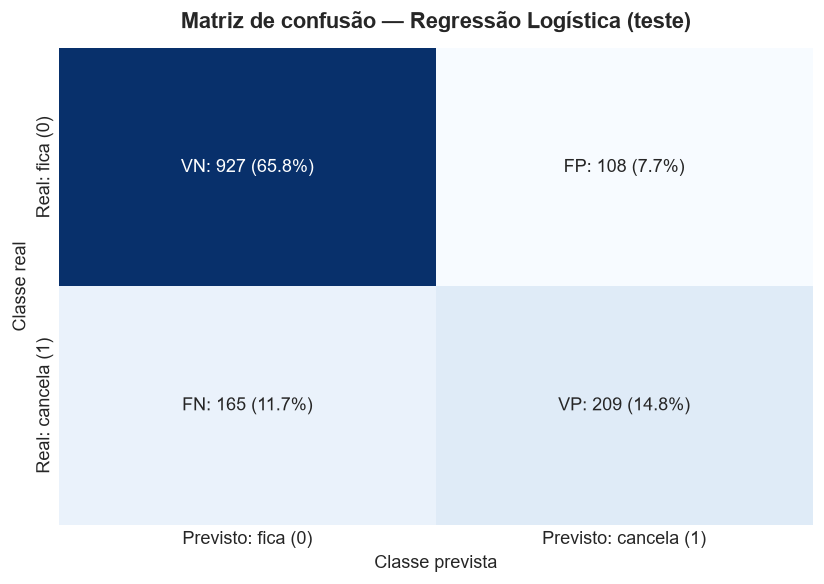

In [18]:
# Matriz de confusao da Regressao Logistica
cm_c_lr = confusion_matrix(y_c_te, y_pred_c_lr)
tn, fp, fn, tp = cm_c_lr.ravel()

plt.figure(figsize=(7, 5))
n_tot = len(y_c_te)
labels_cm = np.array([[f"VN: {tn} (" + "{:.1f}%)".format(tn/n_tot*100), f"FP: {fp} (" + "{:.1f}%)".format(fp/n_tot*100)],
                      [f"FN: {fn} (" + "{:.1f}%)".format(fn/n_tot*100), f"VP: {tp} (" + "{:.1f}%)".format(tp/n_tot*100)]])
sns.heatmap(cm_c_lr, annot=labels_cm, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: fica (0)', 'Previsto: cancela (1)'],
            yticklabels=['Real: fica (0)', 'Real: cancela (1)'])
plt.title("Matriz de confusão — Regressão Logística (teste)", fontsize=13, fontweight='bold', pad=12)
plt.ylabel("Classe real", fontsize=11)
plt.xlabel("Classe prevista", fontsize=11)
plt.tight_layout()
plt.show()


### 2.5 O que é pior: falso positivo ou falso negativo?
**O falso negativo é pior para esta empresa.**
- **Falso positivo** (108 clientes): o modelo diz que o cliente vai cancelar, mas ele ia ficar. A empresa dá um desconto que não precisava — um custo limitado e conhecido.
- **Falso negativo** (165 clientes): o modelo diz que o cliente vai ficar, mas ele cancela. Nenhuma ação é tomada e a empresa **perde toda a receita futura desse cliente**. Além disso, conquistar um cliente novo para repor costuma custar mais caro do que manter um atual.

Por isso vale **baixar o limiar de decisão** (o padrão é 0,50), aceitando mais falsos positivos para perder menos clientes:


In [19]:
# Recall x precisao da Regressao Logistica para diferentes limiares de decisao
print(f"{'Limiar':>7s} {'Recall':>8s} {'Precisao':>9s} {'FP':>5s} {'FN':>5s}")
for limiar in [0.50, 0.40, 0.35, 0.30, 0.25]:
    pred_limiar = (y_prob_c_lr >= limiar).astype(int)
    fp_l = int(((pred_limiar == 1) & (y_c_te == 0)).sum())
    fn_l = int(((pred_limiar == 0) & (y_c_te == 1)).sum())
    print(f"{limiar:7.2f} {recall_score(y_c_te, pred_limiar)*100:7.1f}% {precision_score(y_c_te, pred_limiar)*100:8.1f}% {fp_l:5d} {fn_l:5d}")


 Limiar   Recall  Precisao    FP    FN
   0.50    55.9%     65.9%   108   165
   0.40    66.6%     57.0%   188   125
   0.35    70.3%     54.5%   220   111
   0.30    75.7%     52.0%   261    91
   0.25    80.7%     49.8%   305    72


Com limiar **0,30**, o modelo identifica 3 de cada 4 clientes que vão cancelar (recall de 75,7%): são 74 clientes a mais retidos no teste, ao custo de 153 descontos a mais. A escolha final depende do valor do desconto comparado ao valor de um cliente perdido.


---
# PARTE 2: Aprendizado Não Supervisionado

## Problema 3: Clusterização — "O Perfil do Consumidor"

O marketing de um shopping quer agrupar os clientes por renda anual e pontuação de gastos, sem rótulos prévios.

### 3.1 Escalonamento
O K-Means agrupa pela **distância euclidiana**, então uma variável com valores muito maiores domina a distância e a outra quase não conta. Antes de decidir, conferimos as escalas:


In [20]:
# Carga do dataset Mall Customers
caminho_p3 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 3/Mall_Customers.csv'
df_mall = pd.read_csv(caminho_p3)
print(f"Dataset carregado: {df_mall.shape[0]} clientes e {df_mall.shape[1]} colunas.")

features_mall = ['Annual Income (k$)', 'Spending Score (1-100)']
X_mall = df_mall[features_mall].copy()
print(X_mall.describe().T[['min', 'max', 'std']].round(2).to_string())

# Padronizacao: media 0 e desvio padrao 1 para as duas variaveis
scaler_mall = StandardScaler()
X_mall_scaled = scaler_mall.fit_transform(X_mall)
print("\nStandardScaler aplicado.")


Dataset carregado: 200 clientes e 5 colunas.
                         min    max    std
Annual Income (k$)      15.0  137.0  26.26
Spending Score (1-100)   1.0   99.0  25.82

StandardScaler aplicado.


**Neste dataset, as escalas já são parecidas:** a renda está em milhares (15 a 137, desvio padrão 26,3) e a pontuação vai de 1 a 99 (desvio padrão 25,8). Se a renda estivesse em reais (30.000 a 150.000), ela dominaria a distância.

Mesmo assim, aplicamos o **`StandardScaler`** (`z = (x − média) ÷ desvio padrão`) como boa prática: as duas variáveis ficam com média 0 e desvio padrão 1, e garantimos que nenhuma pese mais que a outra.

### 3.2 Quantidade de clusters: Método do Cotovelo
Treinamos o K-Means com K de 1 a 10 e registramos a **inércia** (soma das distâncias de cada cliente ao centro do seu grupo). Como apoio, calculamos o **coeficiente de silhueta** (quanto mais perto de 1, mais separados os grupos).


K =  1 | Inercia =  400.00 | Silhueta =   -   
K =  2 | Inercia =  269.69 | Silhueta = 0.3213
K =  3 | Inercia =  157.70 | Silhueta = 0.4666
K =  4 | Inercia =  108.92 | Silhueta = 0.4939
K =  5 | Inercia =   65.57 | Silhueta = 0.5547
K =  6 | Inercia =   55.06 | Silhueta = 0.5399
K =  7 | Inercia =   44.86 | Silhueta = 0.5281
K =  8 | Inercia =   37.23 | Silhueta = 0.4552
K =  9 | Inercia =   32.39 | Silhueta = 0.4571
K = 10 | Inercia =   29.98 | Silhueta = 0.4432


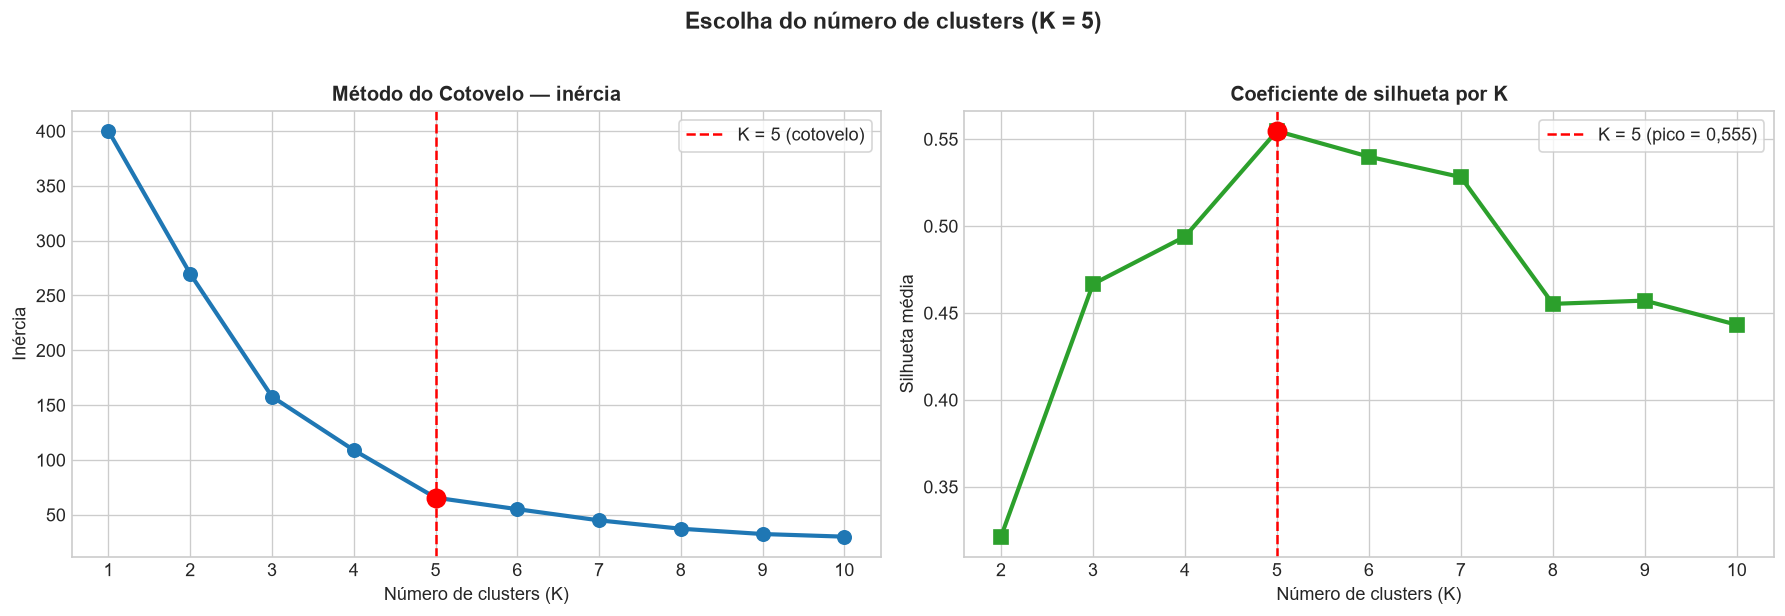

In [21]:
# Inercia e silhueta para K de 1 a 10
inercia_lista = []
silhuetas_lista = []
k_valores = list(range(1, 11))

for k in k_valores:
    km = KMeans(n_clusters=k, init='k-means++', random_state=SEED, n_init=10)
    km.fit(X_mall_scaled)
    inercia_lista.append(km.inertia_)
    if k >= 2:
        silhuetas_lista.append(silhouette_score(X_mall_scaled, km.labels_))

for k in k_valores:
    silh = f"{silhuetas_lista[k-2]:.4f}" if k >= 2 else "  -   "
    print(f"K = {k:2d} | Inercia = {inercia_lista[k-1]:7.2f} | Silhueta = {silh}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_valores, inercia_lista, marker='o', linewidth=2.5, color='#1f77b4', markersize=8)
axes[0].axvline(5, color='red', linestyle='--', linewidth=1.5, label='K = 5 (cotovelo)')
axes[0].scatter(5, inercia_lista[4], color='red', s=120, zorder=5)
axes[0].set_title("Método do Cotovelo — inércia", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Número de clusters (K)", fontsize=11)
axes[0].set_ylabel("Inércia", fontsize=11)
axes[0].set_xticks(k_valores)
axes[0].legend(frameon=True)

axes[1].plot(range(2, 11), silhuetas_lista, marker='s', linewidth=2.5, color='#2ca02c', markersize=8)
axes[1].axvline(5, color='red', linestyle='--', linewidth=1.5, label='K = 5 (pico = 0,555)')
axes[1].scatter(5, silhuetas_lista[3], color='red', s=120, zorder=5)
axes[1].set_title("Coeficiente de silhueta por K", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Número de clusters (K)", fontsize=11)
axes[1].set_ylabel("Silhueta média", fontsize=11)
axes[1].set_xticks(range(2, 11))
axes[1].legend(frameon=True)

plt.suptitle("Escolha do número de clusters (K = 5)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Escolhemos K = 5.** Até K = 5, cada cluster a mais reduz bastante a inércia (de 108,9 para 65,6 ao passar de 4 para 5). Depois disso, o ganho fica pequeno (de 65,6 para 55,1 ao passar para 6) — é o "cotovelo" da curva. A silhueta confirma: é maior em K = 5 (0,555).

### 3.3 Treino e visualização


   Renda media (k$)  Gasto medio (1-100)  Clientes
0              55.3                 49.5        81
1              86.5                 82.1        39
2              25.7                 79.4        22
3              88.2                 17.1        35
4              26.3                 20.9        23


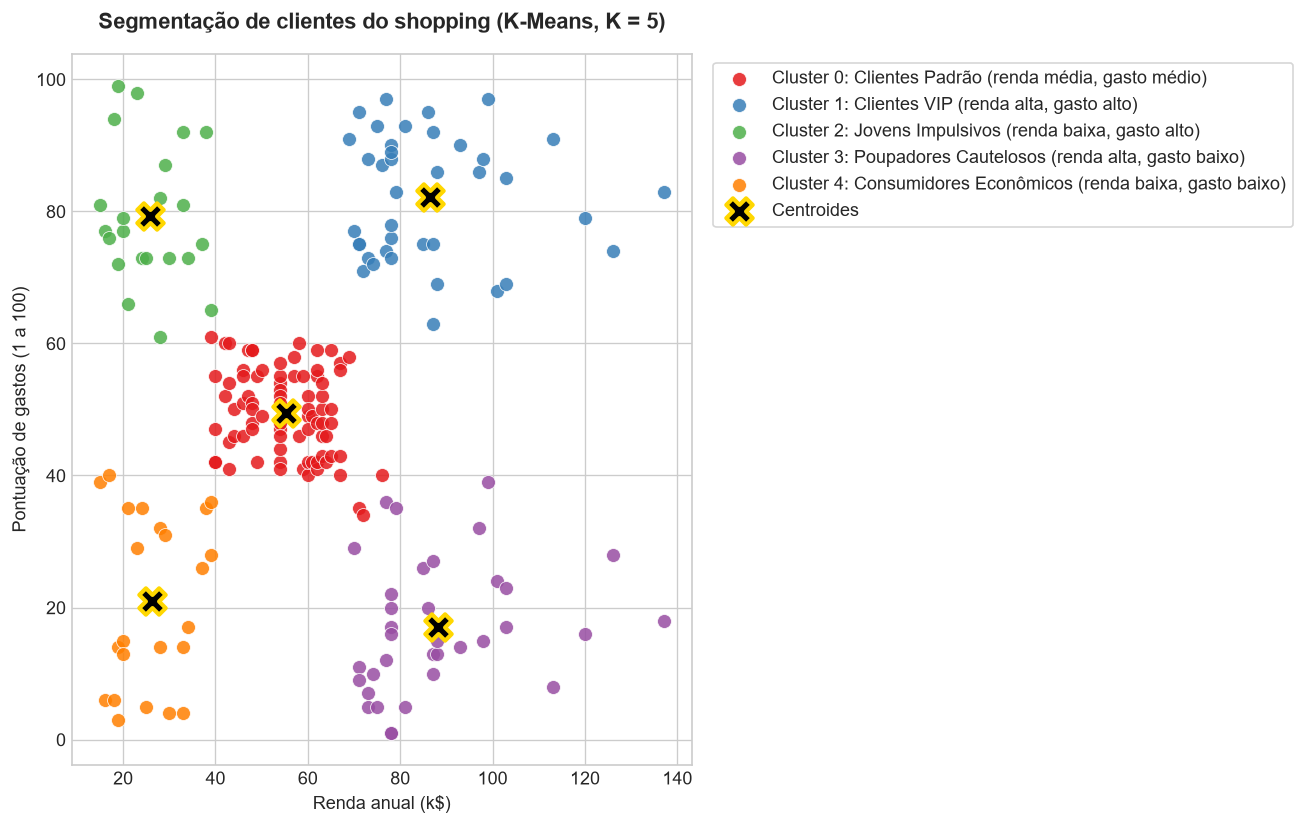

In [22]:
# K-Means final com K = 5
km_final = KMeans(n_clusters=5, init='k-means++', random_state=SEED, n_init=15)
df_mall['Cluster'] = km_final.fit_predict(X_mall_scaled)

centroides_orig = scaler_mall.inverse_transform(km_final.cluster_centers_)
resumo_mall = pd.DataFrame(centroides_orig, columns=['Renda media (k$)', 'Gasto medio (1-100)']).round(1)
resumo_mall['Clientes'] = df_mall['Cluster'].value_counts().sort_index()
print(resumo_mall.to_string())

plt.figure(figsize=(11, 7))
cores_mall = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
nomes_clusters = {
    0: "Cluster 0: Clientes Padrão (renda média, gasto médio)",
    1: "Cluster 1: Clientes VIP (renda alta, gasto alto)",
    2: "Cluster 2: Jovens Impulsivos (renda baixa, gasto alto)",
    3: "Cluster 3: Poupadores Cautelosos (renda alta, gasto baixo)",
    4: "Cluster 4: Consumidores Econômicos (renda baixa, gasto baixo)"
}

for c_id in range(5):
    sub = df_mall[df_mall['Cluster'] == c_id]
    plt.scatter(sub['Annual Income (k$)'], sub['Spending Score (1-100)'],
                s=70, alpha=0.85, label=nomes_clusters[c_id],
                color=cores_mall[c_id], edgecolors='white', linewidth=0.5)

plt.scatter(centroides_orig[:, 0], centroides_orig[:, 1],
            s=250, c='black', marker='X', edgecolors='gold', linewidth=2.5,
            label='Centroides', zorder=10)

plt.title("Segmentação de clientes do shopping (K-Means, K = 5)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Renda anual (k$)", fontsize=11)
plt.ylabel("Pontuação de gastos (1 a 100)", fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 3.4 Interpretação de negócio: nomes dos grupos

| Cluster | Perfil | Nome comercial | Ação de marketing |
| :---: | --- | --- | --- |
| 1 | Renda alta, gasto alto | **Clientes VIP** | Lançamentos exclusivos, eventos fechados, atendimento personalizado |
| 2 | Renda baixa, gasto alto | **Jovens Impulsivos** | Parcelamento, cartão da loja, promoções relâmpago nas redes sociais |
| 0 | Renda média, gasto médio | **Clientes Padrão** | Programa de pontos, campanhas de datas comemorativas |
| 3 | Renda alta, gasto baixo | **Poupadores Cautelosos** | Destacar qualidade, durabilidade e garantia |
| 4 | Renda baixa, gasto baixo | **Consumidores Econômicos** | Cupons, liquidações e ofertas de custo-benefício |

O grupo mais interessante é o dos **Poupadores Cautelosos**: têm tanto dinheiro quanto os VIPs, mas gastam pouco no shopping.


---
## Problema 4: Clusterização Musical — "Criando a Playlist Perfeita"

Um app de streaming quer 5 playlists automáticas baseadas só nas propriedades acústicas das músicas, sem usar o gênero.

### 4.1 Limpeza e filtragem
**As colunas de texto ajudam a calcular distâncias? Não.** `track_id`, `artists`, `album_name`, `track_name` e `track_genre` são nomes e códigos: não existe distância entre "Coldplay" e "Metallica", e numerar os artistas (1, 2, 3…) faria o algoritmo achar que o artista 101 é "parecido" com o 102.

O que fizemos:
1. Retiramos as colunas de texto do treino, mas as mantivemos na tabela para consultar os nomes depois. O gênero só é usado no final, para conferir os grupos.
2. Removemos as **duplicatas de `track_id`**: a mesma música aparece uma vez para cada gênero em que foi cadastrada, e pesaria em dobro.
3. Usamos 9 atributos acústicos numéricos, padronizados com `StandardScaler`.
4. Deixamos de fora `key` (tom) e `mode`: são códigos de categoria (0 = Dó, 1 = Dó#, …), e a distância entre os números não tem sentido musical.


In [23]:
# Carga do dataset do Spotify
caminho_p4 = '4-bloco-Machine Learing/TRABALHO AV1/Problema 4/dataset.csv'
df_spotify = pd.read_csv(caminho_p4)
print(f"Dataset carregado: {df_spotify.shape[0]} linhas e {df_spotify.shape[1]} colunas.")

# Atributos acusticos usados no agrupamento (sem texto, sem key/mode)
features_musica = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

df_sp_clean = df_spotify.dropna(subset=features_musica + ['track_name']).copy()
df_sp_clean = df_sp_clean.drop_duplicates(subset='track_id')
print(f"Faixas unicas apos remover nulos e duplicatas: {len(df_sp_clean)}")


Dataset carregado: 114000 linhas e 21 colunas.
Faixas unicas apos remover nulos e duplicatas: 89740


### 4.2 Correlação entre `energy` e `acousticness`


In [24]:
# Correlacao de Pearson
r_ea = df_sp_clean['energy'].corr(df_sp_clean['acousticness'])
print(f"Correlacao (energy vs acousticness): r = {r_ea:.4f}")


Correlacao (energy vs acousticness): r = -0.7326


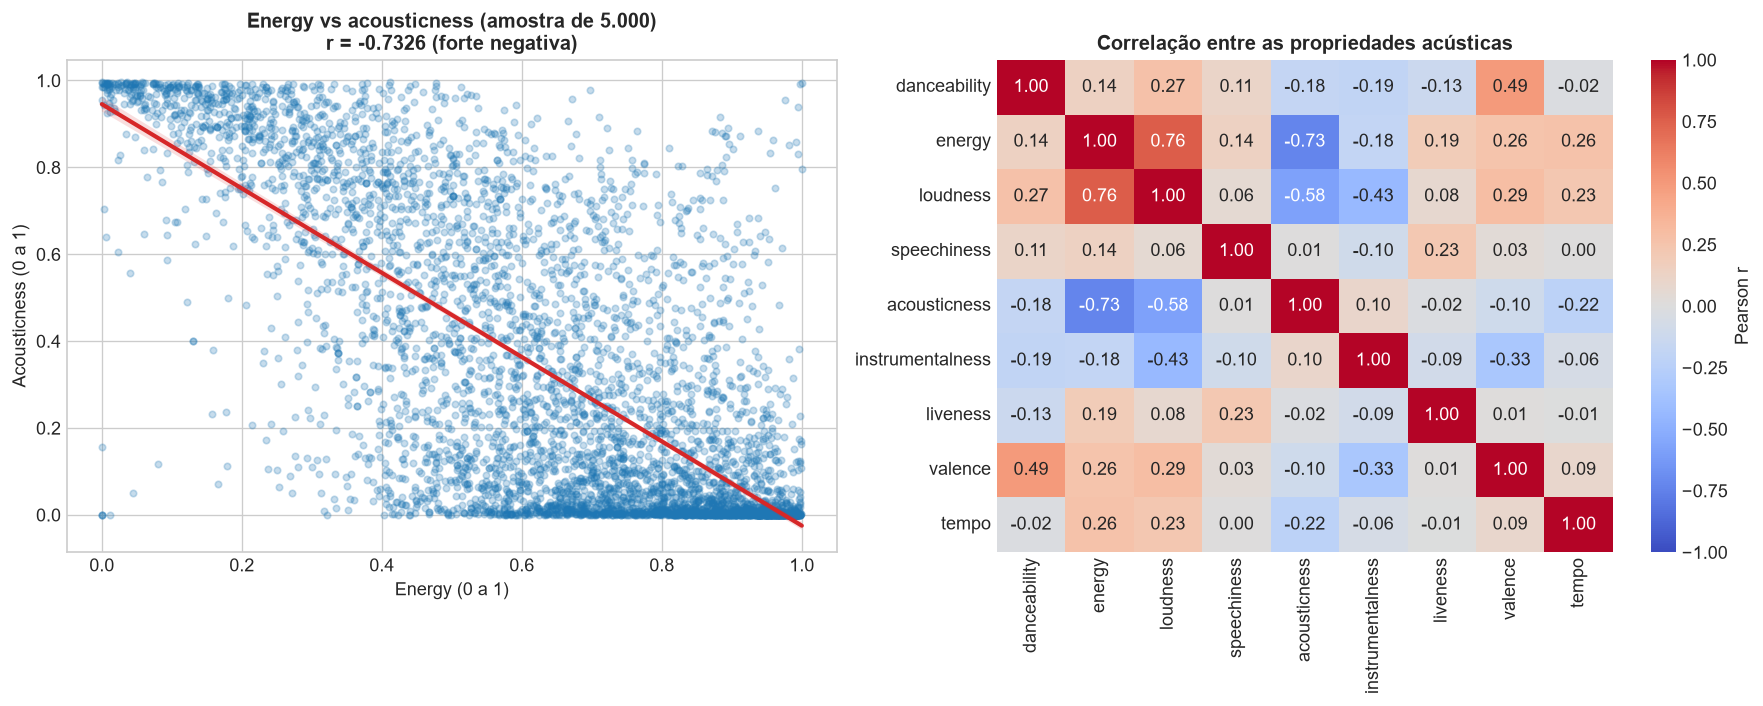

In [25]:
# Grafico da relacao entre energy e acousticness
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

amostra_sp = df_sp_clean.sample(n=5000, random_state=SEED)
sns.regplot(data=amostra_sp, x='energy', y='acousticness', ax=axes[0],
            scatter_kws={'alpha': 0.25, 'color': '#1f77b4', 's': 15},
            line_kws={'color': '#d62728', 'linewidth': 2.5})
axes[0].set_title(f"Energy vs acousticness (amostra de 5.000)\nr = {r_ea:.4f} (forte negativa)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Energy (0 a 1)", fontsize=11)
axes[0].set_ylabel("Acousticness (0 a 1)", fontsize=11)

sns.heatmap(df_sp_clean[features_musica].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Pearson r'})
axes[1].set_title("Correlação entre as propriedades acústicas", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


**Sim, há uma correlação negativa forte (r ≈ −0,73).** Músicas mais acústicas (violão, piano, voz sem efeitos) tendem a ser mais calmas, e músicas com muita energia (rock pesado, eletrônica) quase sempre usam instrumentos elétricos, sintetizadores e volume alto. É raro uma música ser ao mesmo tempo muito acústica e muito agitada — mas existem exceções (um forró pé de serra pode ser acústico e animado), por isso a correlação é forte, mas não perfeita.

### 4.3 Treino: K-Means com 5 clusters


In [26]:
# Padronizacao e K-Means com K = 5
scaler_sp = StandardScaler()
X_sp_scaled = scaler_sp.fit_transform(df_sp_clean[features_musica])

km_sp = KMeans(n_clusters=5, init='k-means++', random_state=SEED, n_init=10)
df_sp_clean['cluster'] = km_sp.fit_predict(X_sp_scaled)

# Media de cada atributo por cluster (escala original)
perfil_sp = df_sp_clean.groupby('cluster')[features_musica].mean().round(2)
perfil_sp['faixas'] = df_sp_clean['cluster'].value_counts().sort_index()
print(perfil_sp.to_string())


         danceability  energy  loudness  speechiness  acousticness  instrumentalness  liveness  valence   tempo  faixas
cluster                                                                                                                
0                0.48    0.82     -5.99         0.08          0.07              0.24      0.26     0.32  136.20   26856
1                0.53    0.39    -10.49         0.06          0.67              0.06      0.19     0.40  113.80   20830
2                0.69    0.73     -6.54         0.09          0.21              0.06      0.19     0.69  120.66   33656
3                0.35    0.20    -20.72         0.05          0.82              0.78      0.17     0.18  103.09    7296
4                0.57    0.67    -11.09         0.83          0.73              0.01      0.67     0.45  101.82    1102


Cada cluster recebe o nome do atributo em que mais se destaca (maior centroide padronizado), sem repetir nomes. Depois, conferimos os gêneros mais comuns de cada grupo — lembrando que o gênero **não** foi usado no treino:


In [27]:
# Nome de cada playlist: atributo em que o cluster mais se destaca, sem repetir
nomes_por_feature = {
    'speechiness': "Falado & Stand-up",
    'instrumentalness': "Calmaria Instrumental",
    'acousticness': "Acústico com Voz",
    'energy': "Pesado & Adrenalina",
    'danceability': "Festa & Dança",
}
centroides_z = pd.DataFrame(km_sp.cluster_centers_, columns=features_musica)
pares = centroides_z[list(nomes_por_feature)].stack().sort_values(ascending=False)
nomes_playlists = {}
for (c_id, feature), _ in pares.items():
    if c_id not in nomes_playlists and nomes_por_feature[feature] not in nomes_playlists.values():
        nomes_playlists[c_id] = nomes_por_feature[feature]

for c_id in sorted(nomes_playlists):
    generos = df_sp_clean.loc[df_sp_clean['cluster'] == c_id, 'track_genre'].value_counts().head(4)
    print(f"Cluster {c_id} - {nomes_playlists[c_id]:22s} | generos mais comuns: {', '.join(generos.index)}")


Cluster 0 - Pesado & Adrenalina    | generos mais comuns: grindcore, black-metal, death-metal, heavy-metal
Cluster 1 - Acústico com Voz       | generos mais comuns: tango, honky-tonk, cantopop, romance
Cluster 2 - Festa & Dança          | generos mais comuns: salsa, dancehall, forro, kids
Cluster 3 - Calmaria Instrumental  | generos mais comuns: sleep, new-age, ambient, classical
Cluster 4 - Falado & Stand-up      | generos mais comuns: comedy, show-tunes, kids, children


Os grupos batem com o que se espera de cada estilo: o algoritmo separou metal, música dançante, música acústica cantada, música para relaxar e até áudios de comédia, olhando só para os números do som.

### 4.4 A prova de fogo
Escolhemos o cluster **Calmaria Instrumental** e sorteamos 5 músicas entre as mais populares dele (popularidade ≥ 70), para que pudéssemos conhecer as faixas:


In [28]:
# 5 musicas do cluster 'Calmaria Instrumental', sorteadas entre as populares
id_calmaria = next(c for c, n in nomes_playlists.items() if n == "Calmaria Instrumental")
populares = df_sp_clean[(df_sp_clean['cluster'] == id_calmaria) & (df_sp_clean['popularity'] >= 70)]
amostra_cluster = populares.sample(n=5, random_state=SEED)

print(f"Cluster {id_calmaria} - Calmaria Instrumental ({len(populares)} faixas populares)")
print("=" * 70)
for i, (_, row) in enumerate(amostra_cluster.iterrows(), 1):
    print(f"{i}. {row['artists']} - '{row['track_name']}' (genero cadastrado: {row['track_genre']})")
    print(f"   [Acousticness: {row['acousticness']:.2f} | Instrumentalness: {row['instrumentalness']:.2f} | "
          f"Energy: {row['energy']:.2f} | Loudness: {row['loudness']:.1f} dB]")
print("=" * 70)


Cluster 3 - Calmaria Instrumental (34 faixas populares)
1. Bon Iver - 'Beach Baby' (genero cadastrado: folk)
   [Acousticness: 0.98 | Instrumentalness: 0.41 | Energy: 0.08 | Loudness: -17.3 dB]
2. Clairo - 'Bubble Gum' (genero cadastrado: indie-pop)
   [Acousticness: 0.98 | Instrumentalness: 0.00 | Energy: 0.02 | Loudness: -24.6 dB]
3. Little Circuits - 'Beautiful Imagination' (genero cadastrado: sleep)
   [Acousticness: 0.80 | Instrumentalness: 0.93 | Energy: 0.03 | Loudness: -34.2 dB]
4. Sohn Aelia - 'Herinneringen' (genero cadastrado: sleep)
   [Acousticness: 0.99 | Instrumentalness: 0.91 | Energy: 0.00 | Loudness: -37.2 dB]
5. Yiruma - 'River Flows In You' (genero cadastrado: classical)
   [Acousticness: 0.99 | Instrumentalness: 0.94 | Energy: 0.22 | Loudness: -21.3 dB]


**Faz sentido estarem na mesma playlist? Sim, para uma playlist de relaxar, estudar ou dormir.** As cinco são muito acústicas, têm energia quase zero e volume baixo. *River Flows In You* (Yiruma, piano solo) e as duas faixas de "sleep" são instrumentais e tranquilas; as músicas de Bon Iver e Clairo, mesmo tendo voz, são sussurradas e minimalistas, no mesmo clima.

O agrupamento juntou músicas de 4 gêneros cadastrados diferentes (folk, indie-pop, sleep, classical) pelo **clima** do som, que era o objetivo. A ressalva: as faixas de "sleep" são mais um som de fundo do que músicas para ouvir com atenção, então quem ouvisse a playlist notaria a diferença entre elas e as canções.


---
## Resumo dos resultados

| Problema | Algoritmo | Principais resultados |
| --- | --- | --- |
| **1. O Preço Justo** | Regressão Linear; Ridge + Gradient Boosting (competição) | R² baseline = 0,823; modelo da competição com MAE = US\$ 11.773 |
| **2. A Ameaça do Churn** | Regressão Logística e Random Forest | ROC-AUC = 0,842; recall do churn de 55,9% (75,7% com limiar 0,30) |
| **3. O Perfil do Consumidor** | K-Means (K = 5) | Silhueta = 0,555; 5 perfis de cliente |
| **4. A Playlist Perfeita** | K-Means (K = 5) | r(energy, acousticness) = −0,73; 5 playlists coerentes com os gêneros |
